In [1]:
%pip install optuna


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


2026-11-06 15:59:04.360 | INFO     | __main__:<module>:55 - Thư mục gốc dự án (BASE_DIR): /home/trang/DemandCast
2026-11-06 15:59:04.361 | INFO     | __main__:<module>:56 - Đọc dữ liệu Gold từ: /home/trang/DemandCast/data/3_gold/weekly_demand_features_calendar_fixed.parquet
2026-11-06 15:59:04.362 | SUCCESS  | __main__:<module>:62 - Đường dẫn hợp lệ. Sẵn sàng train mô hình!
2026-11-06 15:59:04.446 | INFO     | __main__:<module>:70 - Loaded Gold Dataset: 301,631 rows | 20 columns
2026-11-06 15:59:04.562 | SUCCESS  | __main__:<module>:99 - Features Roster V4 (16 features): ['Weekly_Demand', 'Weekly_Revenue', 'Avg_UnitPrice', 'Lag_1W', 'Lag_2W', 'Lag_4W', 'Rolling_Mean_4W', 'Rolling_Std_4W', 'Month', 'Quarter', 'Year', 'Is_Peak_Season', 'Demand_Trend_Ratio', 'Demand_CV', 'Price_Ratio_Vs_Avg', 'Is_Zero_Demand']
2026-11-06 15:59:04.597 | INFO     | __main__:<module>:115 - Train Range      : 2009-12-28 to 2011-10-03 (280,001 rows)
2026-11-06 15:59:04.599 | INFO     | __main__:<module>:116 - 


shape: (8, 6)
┌──────────────────────────────┬──────┬───────────┬─────────────┬───────────┬───────────┐
│ Model                        ┆ Set  ┆ MAE       ┆ RMSE        ┆ WAPE (%)  ┆ Bias (%)  │
│ ---                          ┆ ---  ┆ ---       ┆ ---         ┆ ---       ┆ ---       │
│ str                          ┆ str  ┆ f64       ┆ f64         ┆ f64       ┆ f64       │
╞══════════════════════════════╪══════╪═══════════╪═════════════╪═══════════╪═══════════╡
│ 1. Seasonal Naïve (Baseline) ┆ Val  ┆ 41.1699   ┆ 147.8253    ┆ 76.45     ┆ -8.31     │
│ 1. Seasonal Naïve (Baseline) ┆ Test ┆ 45.0119   ┆ 115.7171    ┆ 71.07     ┆ 2.86      │
│ 2. Ridge Regression          ┆ Val  ┆ 1932.0445 ┆ 100975.2769 ┆ 3587.91   ┆ 3458.81   │
│ 2. Ridge Regression          ┆ Test ┆ 5.8051e12 ┆ 5.5308e14   ┆ 9.1663e12 ┆ 9.1663e12 │
│ 3. LightGBM Regressor        ┆ Val  ┆ 31.9887   ┆ 127.7428    ┆ 59.4      ┆ -39.22    │
│ 3. LightGBM Regressor        ┆ Test ┆ 35.5144   ┆ 117.1263    ┆ 56.08     ┆ -26.34 

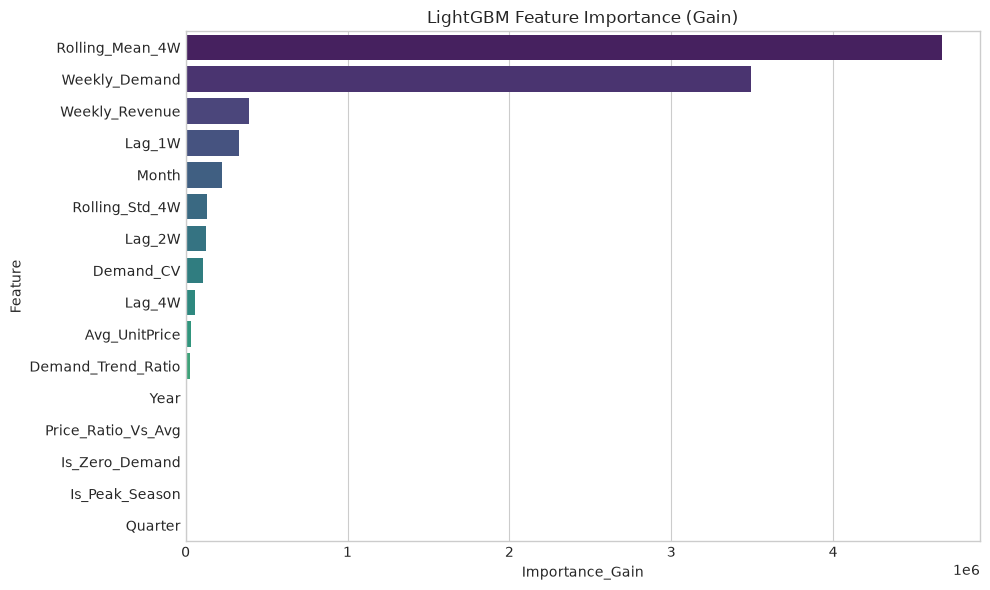

2026-11-06 15:59:10.698 | INFO     | __main__:<module>:286 - Sub-Group Evaluation (LightGBM MAE):
2026-11-06 15:59:10.699 | INFO     | __main__:<module>:287 -  ├─ Zero-Demand Weeks  : MAE = 6.2905
2026-11-06 15:59:10.699 | INFO     | __main__:<module>:288 -  └─ Active Demand Weeks : MAE = 41.1396
2026-11-06 15:59:10.739 | SUCCESS  | __main__:<module>:298 - Final Model Saved to: /home/trang/DemandCast/models/best_lightgbm_model_v4.pkl
2026-11-06 15:59:10.740 | SUCCESS  | __main__:<module>:299 - Predictions Exported to: /home/trang/DemandCast/reports/test_predictions_v4.parquet


In [1]:
# ==============================================================================
# 📥 PHASE 1: IMPORTS & WORKSPACE SETUP
# ==============================================================================
import os
from pathlib import Path
from datetime import timedelta
import warnings
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from loguru import logger

# Machine Learning & Metrics
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Tìm thư mục gốc dựa trên project marker và đúng file Gold cần dùng.
current_dir = Path.cwd().resolve()
gold_filename = "weekly_demand_features_calendar_fixed.parquet"
BASE_DIR = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "pyproject.toml").is_file()
        and (path / "data" / "3_gold" / gold_filename).is_file()
    ),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError(
        f"Could not locate project root containing data/3_gold/{gold_filename} "
        f"from the current directory: {current_dir}"
    )

# Thiết lập đường dẫn chính xác theo cây thư mục gốc
GOLD_DIR = BASE_DIR / "data" / "3_gold"
MODEL_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# Đảm bảo các thư mục đầu ra tồn tại
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

GOLD_PATH = GOLD_DIR / gold_filename

logger.info(f"Thư mục gốc dự án (BASE_DIR): {BASE_DIR.resolve()}")
logger.info(f"Đọc dữ liệu Gold từ: {GOLD_PATH.resolve()}")

# Kiểm tra file tồn tại trước khi đọc
if not GOLD_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy file tại: {GOLD_PATH.resolve()}")
else:
    logger.success("Đường dẫn hợp lệ. Sẵn sàng train mô hình!")
# ==============================================================================
# 🧹 PHASE 2, 3 & 8: DATA LOADING & PREPROCESSING (Tasks 11 - 46, 134 - 146)
# ==============================================================================
if not GOLD_PATH.is_file():
    raise FileNotFoundError(f"Cannot find Gold Parquet at {GOLD_PATH}. Please run Gold Feature Pipeline first.")

df_raw = pl.read_parquet(GOLD_PATH)
logger.info(f"Loaded Gold Dataset: {df_raw.height:,} rows | {len(df_raw.columns)} columns")

# 1. Forward-fill UnitPrice theo SKU và xử lý Null Ratio
df_cleaned = (
    df_raw.sort(["StockCode", "Week_Start"])
    .with_columns([
        # Fill giá bán gần nhất của từng SKU (nếu vẫn NULL thì fill median toàn bộ)
        pl.col("Avg_UnitPrice")
        .forward_fill()
        .over("StockCode")
        .fill_null(pl.col("Avg_UnitPrice").median())
        .alias("Avg_UnitPrice"),
        
        # Ratio khuyết coi như bằng 1.0 (giá không đổi)
        pl.col("Price_Ratio_Vs_Avg").fill_null(1.0).alias("Price_Ratio_Vs_Avg"),
        
        # Đảm bảo Is_Zero_Demand là int8
        (pl.col("Weekly_Demand") == 0).cast(pl.Int8).alias("Is_Zero_Demand")
    ])
)

# 2. Định nghĩa Feature Set V4 (Loại bỏ leakage & cột nhận diện string)
EXCLUDE_COLS = [
    "Week_Start", "Target_Week_Start", "StockCode", 
    "Description", "Target_Demand_Weekly"
]
FEATURE_COLS = [col for col in df_cleaned.columns if col not in EXCLUDE_COLS]
TARGET_COL = "Target_Demand_Weekly"

logger.success(f"Features Roster V4 ({len(FEATURE_COLS)} features): {FEATURE_COLS}")

# ==============================================================================
# ⏳ PHASE 5 & 9: TEMPORAL VALIDATION SPLIT (Tasks 78 - 88, 147 - 155)
# ==============================================================================
# Quy tắc: 8 tuần cuối cùng dành cho Validation (4 tuần) và Test (4 tuần)
max_date = df_cleaned["Week_Start"].max()
test_start_date = max_date - timedelta(weeks=3)     # 4 tuần Test
val_start_date = test_start_date - timedelta(weeks=4) # 4 tuần Validation

df_train = df_cleaned.filter(pl.col("Week_Start") < val_start_date)
df_val = df_cleaned.filter(
    (pl.col("Week_Start") >= val_start_date) & (pl.col("Week_Start") < test_start_date)
)
df_test = df_cleaned.filter(pl.col("Week_Start") >= test_start_date)

logger.info(f"Train Range      : {df_train['Week_Start'].min().date()} to {df_train['Week_Start'].max().date()} ({df_train.height:,} rows)")
logger.info(f"Validation Range : {df_val['Week_Start'].min().date()} to {df_val['Week_Start'].max().date()} ({df_val.height:,} rows)")
logger.info(f"Test Range       : {df_test['Week_Start'].min().date()} to {df_test['Week_Start'].max().date()} ({df_test.height:,} rows)")

# Chuyển đổi X, y cho Sklearn / LightGBM / XGBoost + Biến đổi Target log1p
X_train = df_train.select(FEATURE_COLS).to_numpy()
y_train_raw = df_train.select(TARGET_COL).to_numpy().ravel()
y_train_log = np.log1p(y_train_raw)

X_val = df_val.select(FEATURE_COLS).to_numpy()
y_val_raw = df_val.select(TARGET_COL).to_numpy().ravel()
y_val_log = np.log1p(y_val_raw)

X_test = df_test.select(FEATURE_COLS).to_numpy()
y_test_raw = df_test.select(TARGET_COL).to_numpy().ravel()
y_test_log = np.log1p(y_test_raw)

# ==============================================================================
# 📐 HELPER METRICS (Tasks 167 - 172)
# ==============================================================================
def calculate_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Tính toán MAE, RMSE, WAPE, Bias theo chuẩn bài toán Demand Forecasting."""
    # Clip dự báo không được âm
    y_pred_clipped = np.clip(y_pred, 0, None)
    
    mae = mean_absolute_error(y_true, y_pred_clipped)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred_clipped))
    
    sum_actual = np.sum(y_true)
    wape = (np.sum(np.abs(y_true - y_pred_clipped)) / sum_actual * 100) if sum_actual > 0 else np.nan
    bias = (np.sum(y_pred_clipped - y_true) / sum_actual * 100) if sum_actual > 0 else np.nan
    
    return {
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4),
        "WAPE (%)": round(wape, 2),
        "Bias (%)": round(bias, 2)
    }

results_log = []

# ==============================================================================
# 🤖 PHASE 10: MODEL TRAINING (Tasks 156 - 166)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Baseline: Seasonal Naïve (Lag_1W) (Task 156-157)
# ------------------------------------------------------------------------------
logger.info("Training Model 1/4: Baseline Naïve (Lag_1W)...")
pred_val_naive = df_val.select("Lag_1W").to_numpy().ravel()
pred_test_naive = df_test.select("Lag_1W").to_numpy().ravel()

val_metrics_naive = calculate_metrics(y_val_raw, pred_val_naive)
test_metrics_naive = calculate_metrics(y_test_raw, pred_test_naive)

results_log.append({"Model": "1. Seasonal Naïve (Baseline)", "Set": "Val", **val_metrics_naive})
results_log.append({"Model": "1. Seasonal Naïve (Baseline)", "Set": "Test", **test_metrics_naive})

# ------------------------------------------------------------------------------
# 2. Linear Model: Ridge Regression (Task 158)
# ------------------------------------------------------------------------------
logger.info("Training Model 2/4: Ridge Regression (Log-transformed Target)...")
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train_log)

pred_val_ridge = np.expm1(ridge_model.predict(X_val))
pred_test_ridge = np.expm1(ridge_model.predict(X_test))

results_log.append({"Model": "2. Ridge Regression", "Set": "Val", **calculate_metrics(y_val_raw, pred_val_ridge)})
results_log.append({"Model": "2. Ridge Regression", "Set": "Test", **calculate_metrics(y_test_raw, pred_test_ridge)})

# ------------------------------------------------------------------------------
# 3. Tree Model: LightGBM Regressor (Task 160-162)
# ------------------------------------------------------------------------------
logger.info("Training Model 3/4: LightGBM Regressor...")
lgb_params = {
    "objective": "regression",
    "metric": "rmse",
    "boosting_type": "gbdt",
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "max_depth": 6,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "random_state": 42,
    "verbose": -1
}

lgb_train = lgb.Dataset(X_train, label=y_train_log)
lgb_val = lgb.Dataset(X_val, label=y_val_log, reference=lgb_train)

lgb_model = lgb.train(
    lgb_params,
    lgb_train,
    valid_sets=[lgb_train, lgb_val],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

pred_val_lgb = np.expm1(lgb_model.predict(X_val, num_iteration=lgb_model.best_iteration))
pred_test_lgb = np.expm1(lgb_model.predict(X_test, num_iteration=lgb_model.best_iteration))

results_log.append({"Model": "3. LightGBM Regressor", "Set": "Val", **calculate_metrics(y_val_raw, pred_val_lgb)})
results_log.append({"Model": "3. LightGBM Regressor", "Set": "Test", **calculate_metrics(y_test_raw, pred_test_lgb)})

# ------------------------------------------------------------------------------
# 4. Tree Model: XGBoost Regressor (Task 161)
# ------------------------------------------------------------------------------
logger.info("Training Model 4/4: XGBoost Regressor...")
xgb_model = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    tree_method="hist",
    early_stopping_rounds=50
)

xgb_model.fit(
    X_train, y_train_log,
    eval_set=[(X_val, y_val_log)],
    verbose=False
)

pred_val_xgb = np.expm1(xgb_model.predict(X_val))
pred_test_xgb = np.expm1(xgb_model.predict(X_test))

results_log.append({"Model": "4. XGBoost Regressor", "Set": "Val", **calculate_metrics(y_val_raw, pred_val_xgb)})
results_log.append({"Model": "4. XGBoost Regressor", "Set": "Test", **calculate_metrics(y_test_raw, pred_test_xgb)})

# ==============================================================================
# 📊 PHASE 11: EVALUATION & ERROR ANALYSIS (Tasks 167 - 191)
# ==============================================================================
df_results = pl.DataFrame(results_log)
print("\n" + "="*70)
logger.success("MODEL EVALUATION SUMMARY BENCHMARK:")
print(df_results)
print("="*70)

# 1. Feature Importance (LightGBM)
importance = lgb_model.feature_importance(importance_type="gain")
df_importance = (
    pl.DataFrame({"Feature": FEATURE_COLS, "Importance_Gain": importance})
    .sort("Importance_Gain", descending=True)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_importance.to_pandas(), 
    x="Importance_Gain", y="Feature", 
    palette="viridis"
)
plt.title("LightGBM Feature Importance (Gain)")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "feature_importance_lgb.png")
plt.show()

# 2. Error Analysis on Intermittent / Zero Demand Group (Task 183)
df_test_eval = df_test.with_columns([
    pl.Series("Pred_LGB", pred_test_lgb),
    pl.Series("Pred_Naive", pred_test_naive)
])

df_zero_demand = df_test_eval.filter(pl.col("Is_Zero_Demand") == 1)
df_active_demand = df_test_eval.filter(pl.col("Is_Zero_Demand") == 0)

mae_zero_lgb = mean_absolute_error(df_zero_demand["Target_Demand_Weekly"], df_zero_demand["Pred_LGB"])
mae_active_lgb = mean_absolute_error(df_active_demand["Target_Demand_Weekly"], df_active_demand["Pred_LGB"])

logger.info(f"Sub-Group Evaluation (LightGBM MAE):")
logger.info(f" ├─ Zero-Demand Weeks  : MAE = {mae_zero_lgb:.4f}")
logger.info(f" └─ Active Demand Weeks : MAE = {mae_active_lgb:.4f}")

# ==============================================================================
# 💾 PHASE 12: FINALIZATION & ARTIFACT PERSISTENCE (Tasks 192 - 205)
# ==============================================================================
# Lưu Model Best Iteration & Predictions
import joblib
joblib.dump(lgb_model, MODEL_DIR / "best_lightgbm_model_v4.pkl")
df_test_eval.write_parquet(REPORTS_DIR / "test_predictions_v4.parquet")

logger.success(f"Final Model Saved to: {MODEL_DIR / 'best_lightgbm_model_v4.pkl'}")
logger.success(f"Predictions Exported to: {REPORTS_DIR / 'test_predictions_v4.parquet'}")

In [3]:
# ==============================================================================
# 🚀 NOTEBOOK 08: MODEL OPTIMIZATION (V5) - TWEEDIE & OPTUNA TUNING
# ==============================================================================
import os
from pathlib import Path
from datetime import timedelta
import warnings
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from loguru import logger

from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import optuna
import joblib

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING) # Giảm log của Optuna cho đỡ rối
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ==============================================================================
# 📥 1. WORKSPACE SETUP & PATH RESOLUTION
# ==============================================================================
# Tìm thư mục gốc dựa trên project marker và đúng file Gold cần dùng
current_dir = Path.cwd().resolve()
gold_filename = "weekly_demand_features_calendar_fixed.parquet"
BASE_DIR = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "pyproject.toml").is_file()
        and (path / "data" / "3_gold" / gold_filename).is_file()
    ),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError(
        f"Could not locate project root containing data/3_gold/{gold_filename} "
        f"from the current directory: {current_dir}"
    )

# Thiết lập đường dẫn chính xác theo cây thư mục gốc
GOLD_DIR = BASE_DIR / "data" / "3_gold"
MODEL_DIR = BASE_DIR / "models"
REPORTS_DIR = BASE_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# Đảm bảo các thư mục đầu ra tồn tại
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

GOLD_PATH = GOLD_DIR / gold_filename

logger.info(f"Thư mục gốc dự án (BASE_DIR): {BASE_DIR.resolve()}")
logger.info(f"Đọc dữ liệu Gold từ: {GOLD_PATH.resolve()}")

# ==============================================================================
# 🧹 2. DATA LOADING & FEATURE PRUNING (Tỉa cành Feature)
# ==============================================================================
df_raw = pl.read_parquet(GOLD_PATH)

# Xử lý Null cho UnitPrice
df_cleaned = (
    df_raw.sort(["StockCode", "Week_Start"])
    .with_columns([
        pl.col("Avg_UnitPrice").forward_fill().over("StockCode").fill_null(pl.col("Avg_UnitPrice").median())
    ])
)

# LOẠI BỎ CÁC FEATURE KÉM HIỆU QUẢ DỰA TRÊN GAIN CHART V4
PRUNED_FEATURES = ["Year", "Price_Ratio_Vs_Avg", "Is_Zero_Demand", "Is_Peak_Season", "Quarter"]
EXCLUDE_COLS = ["Week_Start", "Target_Week_Start", "StockCode", "Description", "Target_Demand_Weekly"] + PRUNED_FEATURES

FEATURE_COLS = [col for col in df_cleaned.columns if col not in EXCLUDE_COLS]
TARGET_COL = "Target_Demand_Weekly"

logger.success(f"Features V5 ({len(FEATURE_COLS)} cột tinh gọn): {FEATURE_COLS}")

# ==============================================================================
# ⏳ 3. TEMPORAL VALIDATION SPLIT
# ==============================================================================
max_date = df_cleaned["Week_Start"].max()
test_start_date = max_date - timedelta(weeks=3)     
val_start_date = test_start_date - timedelta(weeks=4) 

df_train = df_cleaned.filter(pl.col("Week_Start") < val_start_date)
df_val = df_cleaned.filter((pl.col("Week_Start") >= val_start_date) & (pl.col("Week_Start") < test_start_date))
df_test = df_cleaned.filter(pl.col("Week_Start") >= test_start_date)

X_train = df_train.select(FEATURE_COLS).to_numpy()
y_train_raw = df_train.select(TARGET_COL).to_numpy().ravel()

X_val = df_val.select(FEATURE_COLS).to_numpy()
y_val_raw = df_val.select(TARGET_COL).to_numpy().ravel()

X_test = df_test.select(FEATURE_COLS).to_numpy()
y_test_raw = df_test.select(TARGET_COL).to_numpy().ravel()

# BIẾN ĐỔI TARGET BẰNG LOG1P
y_train_log = np.log1p(y_train_raw)
y_val_log = np.log1p(y_val_raw)
y_test_log = np.log1p(y_test_raw)

# ==============================================================================
# 🎯 4. OPTUNA HYPERPARAMETER TUNING (LightGBM Tweedie)
# ==============================================================================
logger.info("Khởi động Optuna: Dò tìm siêu tham số tối ưu cho LightGBM (Tweedie)...")

def objective(trial):
    params = {
        "objective": "tweedie",
        "tweedie_variance_power": trial.suggest_float("tweedie_variance_power", 1.1, 1.9),
        "metric": "rmse",
        "boosting_type": "gbdt",
        "n_estimators": trial.suggest_int("n_estimators", 300, 1500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "max_depth": trial.suggest_int("max_depth", 4, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 0.95),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 0.95),
        "random_state": 42,
        "verbose": -1,
        "n_jobs": -1
    }
    
    lgb_train = lgb.Dataset(X_train, label=y_train_log)
    lgb_val = lgb.Dataset(X_val, label=y_val_log, reference=lgb_train)
    
    model = lgb.train(
        params,
        lgb_train,
        valid_sets=[lgb_train, lgb_val],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    # Đánh giá bằng RMSE trên tập Validation (đã giải Log)
    preds_val = np.expm1(model.predict(X_val))
    preds_val = np.clip(preds_val, 0, None)
    return np.sqrt(mean_squared_error(y_val_raw, preds_val))

# Chạy dò tìm 20 vòng
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

best_params = study.best_params
best_params["objective"] = "tweedie"
best_params["metric"] = "rmse"
best_params["verbose"] = -1
best_params["random_state"] = 42
best_params["n_jobs"] = -1

logger.success(f"Optuna hoàn tất! Best Params: {best_params}")

# ==============================================================================
# 🚂 5. TRAIN FINAL MODEL & EVALUATION
# ==============================================================================
logger.info("Đang huấn luyện mô hình LightGBM cuối cùng với Best Params...")
lgb_train_final = lgb.Dataset(X_train, label=y_train_log)
lgb_val_final = lgb.Dataset(X_val, label=y_val_log, reference=lgb_train_final)

final_model = lgb.train(
    best_params,
    lgb_train_final,
    valid_sets=[lgb_train_final, lgb_val_final],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
)

def calculate_metrics(y_true, y_pred):
    y_pred_clipped = np.clip(y_pred, 0, None)
    mae = mean_absolute_error(y_true, y_pred_clipped)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred_clipped))
    sum_actual = np.sum(y_true)
    wape = (np.sum(np.abs(y_true - y_pred_clipped)) / sum_actual * 100) if sum_actual > 0 else np.nan
    bias = (np.sum(y_pred_clipped - y_true) / sum_actual * 100) if sum_actual > 0 else np.nan
    return {"MAE": round(mae, 4), "RMSE": round(rmse, 4), "WAPE (%)": round(wape, 2), "Bias (%)": round(bias, 2)}

pred_val = np.expm1(final_model.predict(X_val))
pred_test = np.expm1(final_model.predict(X_test))

val_metrics = calculate_metrics(y_val_raw, pred_val)
test_metrics = calculate_metrics(y_test_raw, pred_test)

results = [
    {"Model": "LightGBM (Optuna+Tweedie)", "Set": "Val", **val_metrics},
    {"Model": "LightGBM (Optuna+Tweedie)", "Set": "Test", **test_metrics}
]

df_results = pl.DataFrame(results)
print("\n" + "="*70)
logger.success("ĐÁNH GIÁ MÔ HÌNH V5 (ĐÃ TỐI ƯU):")
print(df_results)
print("="*70)

# ==============================================================================
# 💾 6. SAVE ARTIFACTS
# ==============================================================================
joblib.dump(final_model, MODEL_DIR / "best_lightgbm_optuna_v5.pkl")
logger.success(f"Đã lưu mô hình tinh chỉnh: {MODEL_DIR / 'best_lightgbm_optuna_v5.pkl'}")

2026-11-06 16:06:16.161 | INFO     | __main__:<module>:58 - Thư mục gốc dự án (BASE_DIR): /home/trang/DemandCast
2026-11-06 16:06:16.177 | INFO     | __main__:<module>:59 - Đọc dữ liệu Gold từ: /home/trang/DemandCast/data/3_gold/weekly_demand_features_calendar_fixed.parquet
2026-11-06 16:06:17.139 | SUCCESS  | __main__:<module>:81 - Features V5 (11 cột tinh gọn): ['Weekly_Demand', 'Weekly_Revenue', 'Avg_UnitPrice', 'Lag_1W', 'Lag_2W', 'Lag_4W', 'Rolling_Mean_4W', 'Rolling_Std_4W', 'Month', 'Demand_Trend_Ratio', 'Demand_CV']
2026-11-06 16:06:17.560 | INFO     | __main__:<module>:111 - Khởi động Optuna: Dò tìm siêu tham số tối ưu cho LightGBM (Tweedie)...
2026-11-06 16:07:13.305 | SUCCESS  | __main__:<module>:156 - Optuna hoàn tất! Best Params: {'tweedie_variance_power': 1.3688488779796755, 'n_estimators': 1319, 'learning_rate': 0.08092808274210933, 'num_leaves': 39, 'max_depth': 4, 'subsample': 0.9273349553977248, 'colsample_bytree': 0.7931230445993875, 'objective': 'tweedie', 'metric':


shape: (2, 6)
┌───────────────────────────┬──────┬─────────┬──────────┬──────────┬──────────┐
│ Model                     ┆ Set  ┆ MAE     ┆ RMSE     ┆ WAPE (%) ┆ Bias (%) │
│ ---                       ┆ ---  ┆ ---     ┆ ---      ┆ ---      ┆ ---      │
│ str                       ┆ str  ┆ f64     ┆ f64      ┆ f64      ┆ f64      │
╞═══════════════════════════╪══════╪═════════╪══════════╪══════════╪══════════╡
│ LightGBM (Optuna+Tweedie) ┆ Val  ┆ 31.5512 ┆ 125.9887 ┆ 58.59    ┆ -36.12   │
│ LightGBM (Optuna+Tweedie) ┆ Test ┆ 35.7231 ┆ 109.7456 ┆ 56.41    ┆ -19.21   │
└───────────────────────────┴──────┴─────────┴──────────┴──────────┴──────────┘


In [4]:
# ==============================================================================
# 🚀 NOTEBOOK 09: SKU-LEVEL ERROR ANALYSIS & INFERENCE PIPELINE FINALIZATION
# ==============================================================================
import os
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from loguru import logger
import joblib

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# ==============================================================================
# 📥 1. WORKSPACE SETUP & LOAD ARTIFACTS
# ==============================================================================
current_dir = Path.cwd().resolve()
gold_filename = "weekly_demand_features_calendar_fixed.parquet"
BASE_DIR = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "pyproject.toml").is_file()
        and (path / "data" / "3_gold" / gold_filename).is_file()
    ),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc. Vui lòng kiểm tra lại.")

GOLD_PATH = BASE_DIR / "data" / "3_gold" / gold_filename
MODEL_PATH = BASE_DIR / "models" / "best_lightgbm_optuna_v5.pkl"
REPORTS_DIR = BASE_DIR / "reports"

df_raw = pl.read_parquet(GOLD_PATH)
model_v5 = joblib.load(MODEL_PATH)

logger.info("Đã tải dữ liệu Gold và Mô hình LightGBM V5 thành công.")

# ==============================================================================
# 🔄 2. TÁI TẠO TẬP TEST & DỰ BÁO LẠI (V5)
# ==============================================================================
# Tỉa cành feature giống V5
df_cleaned = df_raw.sort(["StockCode", "Week_Start"]).with_columns([
    pl.col("Avg_UnitPrice").forward_fill().over("StockCode").fill_null(pl.col("Avg_UnitPrice").median())
])

PRUNED_FEATURES = ["Year", "Price_Ratio_Vs_Avg", "Is_Zero_Demand", "Is_Peak_Season", "Quarter"]
EXCLUDE_COLS = ["Week_Start", "Target_Week_Start", "StockCode", "Description", "Target_Demand_Weekly"] + PRUNED_FEATURES
FEATURE_COLS = [col for col in df_cleaned.columns if col not in EXCLUDE_COLS]

# Lọc đúng tập Test (4 tuần cuối)
max_date = df_cleaned["Week_Start"].max()
test_start_date = max_date - pl.duration(weeks=3)
df_test = df_cleaned.filter(pl.col("Week_Start") >= test_start_date)

X_test = df_test.select(FEATURE_COLS).to_numpy()

# Dự báo bằng model V5 (đã giải log1p)
preds_v5 = np.expm1(model_v5.predict(X_test))
preds_v5 = np.clip(preds_v5, 0, None)

df_test_eval = df_test.with_columns([
    pl.Series("Predicted_Demand", preds_v5)
])

# ==============================================================================
# 📊 3. ERROR ANALYSIS THEO TỪNG SKU (GIAI ĐOẠN 11)
# ==============================================================================
logger.info("Đang phân tích sai số trên từng mã SKU...")

sku_analysis = (
    df_test_eval.group_by("StockCode")
    .agg([
        pl.col("Target_Demand_Weekly").sum().alias("Actual_Total"),
        pl.col("Predicted_Demand").sum().alias("Predicted_Total"),
        (pl.col("Target_Demand_Weekly") - pl.col("Predicted_Demand")).abs().sum().alias("Absolute_Error"),
        (pl.col("Predicted_Demand") - pl.col("Target_Demand_Weekly")).sum().alias("Total_Bias")
    ])
    .with_columns([
        # Tính WAPE (%) theo SKU
        (
            pl.when(pl.col("Actual_Total") > 0)
            .then((pl.col("Absolute_Error") / pl.col("Actual_Total")) * 100)
            .otherwise(None)
        ).alias("WAPE_%"),
        
        # Tính Bias (%) theo SKU
        (
            pl.when(pl.col("Actual_Total") > 0)
            .then((pl.col("Total_Bias") / pl.col("Actual_Total")) * 100)
            .otherwise(None)
        ).alias("Bias_%")
    ])
)

# Phân loại SKU theo Volume (Quy mô nhu cầu)
# Tiêu chí: > 100 đơn/4 tuần = High, 10-100 = Medium, < 10 = Low/Intermittent
sku_analysis = sku_analysis.with_columns(
    pl.when(pl.col("Actual_Total") >= 100).then(pl.lit("High Volume"))
    .when(pl.col("Actual_Total") >= 10).then(pl.lit("Medium Volume"))
    .otherwise(pl.lit("Low/Intermittent Volume"))
    .alias("Volume_Segment")
)

# Thống kê WAPE theo nhóm Volume
segment_summary = (
    sku_analysis.group_by("Volume_Segment")
    .agg([
        pl.col("StockCode").count().alias("SKU_Count"),
        pl.col("WAPE_%").median().alias("Median_WAPE_%"),
        pl.col("Bias_%").median().alias("Median_Bias_%")
    ])
    .sort("SKU_Count", descending=True)
)

print("\n" + "="*70)
logger.success("TÓM TẮT SAI SỐ THEO PHÂN KHÚC SKU (VOLUME SEGMENTATION):")
print(segment_summary)
print("="*70)

# Xuất Top 10 SKU dự báo tệ nhất (High Volume nhưng WAPE cao)
worst_skus = (
    sku_analysis.filter(pl.col("Volume_Segment") == "High Volume")
    .sort("WAPE_%", descending=True)
    .head(10)
    .select(["StockCode", "Actual_Total", "Predicted_Total", "WAPE_%", "Bias_%"])
)

print("\n🚨 TOP 10 SKU HIGH-VOLUME CÓ SAI SỐ CAO NHẤT (Cần theo dõi sát):")
print(worst_skus)

# Lưu báo cáo
sku_analysis.write_csv(REPORTS_DIR / "sku_error_analysis_v5.csv")
logger.success(f"Đã xuất báo cáo SKU Error Analysis tại: {REPORTS_DIR / 'sku_error_analysis_v5.csv'}")

# ==============================================================================
# 📦 4. ĐÓNG GÓI INFERENCE PIPELINE (GIAI ĐOẠN 12)
# ==============================================================================
logger.info("Đang khởi tạo Class Inference Pipeline chuẩn bị cho Production...")

class DemandForecaster:
    """
    Class Inference chuẩn Production. 
    Chịu trách nhiệm load model, xử lý dữ liệu mới (features) và trả về dự báo.
    """
    def __init__(self, model_path: str, feature_cols: list):
        self.model = joblib.load(model_path)
        self.feature_cols = feature_cols
        
    def preprocess(self, df_inference: pl.DataFrame) -> np.ndarray:
        # Xử lý null tương tự lúc train
        df_clean = df_inference.with_columns([
            pl.col("Avg_UnitPrice").forward_fill().over("StockCode").fill_null(0.0)
        ])
        
        # Kiểm tra tính toàn vẹn của features
        missing_cols = [col for col in self.feature_cols if col not in df_clean.columns]
        if missing_cols:
            raise ValueError(f"Dữ liệu đầu vào thiếu các cột: {missing_cols}")
            
        return df_clean.select(self.feature_cols).to_numpy()
        
    def predict(self, df_inference: pl.DataFrame) -> pl.DataFrame:
        X_new = self.preprocess(df_inference)
        
        # Dự báo và giải biến đổi log1p
        preds = np.expm1(self.model.predict(X_new))
        preds = np.clip(preds, 0, None) # Không cho phép dự báo âm
        
        return df_inference.with_columns(
            pl.Series("Forecasted_Demand", np.round(preds, 2))
        ).select(["StockCode", "Week_Start", "Forecasted_Demand"])

# Test thử Inference Pipeline
forecaster = DemandForecaster(model_path=MODEL_PATH, feature_cols=FEATURE_COLS)
df_forecast = forecaster.predict(df_test.head(5))

print("\n✅ INFERENCE PIPELINE TEST (Dự báo 5 dòng đầu tiên):")
print(df_forecast)

2026-11-06 16:11:28.807 | INFO     | __main__:<module>:40 - Đã tải dữ liệu Gold và Mô hình LightGBM V5 thành công.
2026-11-06 16:11:29.452 | INFO     | __main__:<module>:72 - Đang phân tích sai số trên từng mã SKU...
2026-11-06 16:11:29.900 | SUCCESS  | __main__:<module>:120 - TÓM TẮT SAI SỐ THEO PHÂN KHÚC SKU (VOLUME SEGMENTATION):
2026-11-06 16:11:30.048 | SUCCESS  | __main__:<module>:137 - Đã xuất báo cáo SKU Error Analysis tại: /home/trang/DemandCast/reports/sku_error_analysis_v5.csv
2026-11-06 16:11:30.050 | INFO     | __main__:<module>:142 - Đang khởi tạo Class Inference Pipeline chuẩn bị cho Production...



shape: (3, 4)
┌─────────────────────────┬───────────┬───────────────┬───────────────┐
│ Volume_Segment          ┆ SKU_Count ┆ Median_WAPE_% ┆ Median_Bias_% │
│ ---                     ┆ ---       ┆ ---           ┆ ---           │
│ str                     ┆ u32       ┆ f64           ┆ f64           │
╞═════════════════════════╪═══════════╪═══════════════╪═══════════════╡
│ High Volume             ┆ 1173      ┆ 57.534398     ┆ -14.869551    │
│ Medium Volume           ┆ 1093      ┆ 78.458194     ┆ -33.455512    │
│ Low/Intermittent Volume ┆ 536       ┆ 99.951599     ┆ -26.997199    │
└─────────────────────────┴───────────┴───────────────┴───────────────┘

🚨 TOP 10 SKU HIGH-VOLUME CÓ SAI SỐ CAO NHẤT (Cần theo dõi sát):
shape: (10, 5)
┌───────────┬──────────────┬─────────────────┬────────────┬────────────┐
│ StockCode ┆ Actual_Total ┆ Predicted_Total ┆ WAPE_%     ┆ Bias_%     │
│ ---       ┆ ---          ┆ ---             ┆ ---        ┆ ---        │
│ str       ┆ i64          ┆ f64      

In [5]:
sku_id = "22711"

sku_error = (
    df_test.with_columns(
        pl.Series("Predicted_Demand", pred_test)
    )
    .filter(pl.col("StockCode") == sku_id)
    .select([
        "Week_Start",
        "Target_Demand_Weekly",
        "Predicted_Demand"
    ])
    .with_columns([
        (pl.col("Predicted_Demand") - pl.col("Target_Demand_Weekly"))
        .alias("Error"),
        (pl.col("Predicted_Demand") - pl.col("Target_Demand_Weekly"))
        .abs().alias("Absolute_Error")
    ])
    .sort("Week_Start")
)

display(sku_error)

Week_Start,Target_Demand_Weekly,Predicted_Demand,Error,Absolute_Error
datetime[μs],i64,f64,f64,f64
2011-11-07 00:00:00,0,82.800407,82.800407,82.800407
2011-11-14 00:00:00,0,18.692,18.692,18.692
2011-11-21 00:00:00,50,7.620336,-42.379664,42.379664
2011-11-28 00:00:00,75,13.571054,-61.428946,61.428946
